# A/B-тест нового чекаута: выкатывать или нет?

**Вопрос бизнеса.** Интернет-магазин заменил оформление заказа из трёх шагов на одностраничное. Тест шёл 14 дней на ~80 тыс. пользователей (50/50). Нужно решить: выкатывать новый чекаут на всех или нет.

**Метрики**
- главная — конверсия в покупку;
- вторая — выручка на пользователя (ARPU);
- защитные — средний чек и доля возвратов (не должны заметно ухудшиться).

Уровень значимости — 5%.

In [1]:
import pandas as pd
from IPython.display import Image, display
from ab.data import connect, query
from ab import analysis, stats as s

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
con = connect()

## 1. Проверка данных: утечка сплита

Сначала ищем пользователей, которые увидели обе версии чекаута. Их нельзя честно отнести ни к одной группе — исключаем (`sql/01_split_leak.sql`).

In [2]:
leaked = query(con, "01_split_leak.sql")
print(f"Пользователей в обеих группах: {len(leaked)}")

Пользователей в обеих группах: 240


Одна строка на пользователя собирается SQL-запросом `sql/02_user_metrics.sql`: исключаем утёкших, берём только заказы после попадания в тест, возвраты не считаем в выручку.

In [3]:
query(con, "03_group_summary.sql")

,group,users,buyers,conversion_pct,revenue,arpu,aov,refund_rate_pct
0,A,39938,"2,441.0000",6.1100,"12,733,286.0000",318.8000,"5,003.0000",5.7400
1,B,39822,"2,746.0000",6.9000,"13,422,199.0000",337.1000,"4,700.0000",6.3900


## 2. SRM — сплит не сломан?

Если доли групп сильно отличаются от 50/50, значит, что-то не так с распределением трафика, и результатам нельзя доверять. Проверяем хи-квадратом.

In [4]:
um = con.execute("SELECT * FROM user_metrics ORDER BY user_id").df()
res = analysis.run(um)
res["srm"]

{'share_a': 0.5007271815446339,
 'chi2': np.float64(0.1687061183550652),
 'p_value': np.float64(0.6812642904311617),
 'ok': np.True_}

p-value далеко от порога 0,001 — сплит в порядке.

**Мощность.** При ~40 тыс. пользователей в группе и базовой конверсии ~6% тест надёжно (с мощностью 80%) замечает эффект от ~0,47 п.п. — примерно 8% относительно. Эффекты меньше этого тест мог бы пропустить.

In [5]:
print(f"MDE: {res['mde']*100:.2f} п.п. ({res['mde']/res['conversion']['p_a']*100:.1f}% относительно)")

MDE: 0.47 п.п. (7.8% относительно)


## 3. Главная метрика — конверсия

A: 6.11%   B: 6.90%
Прирост: +12.8%, 95% ДИ [+7.2%; +18.4%], p = 0.00001


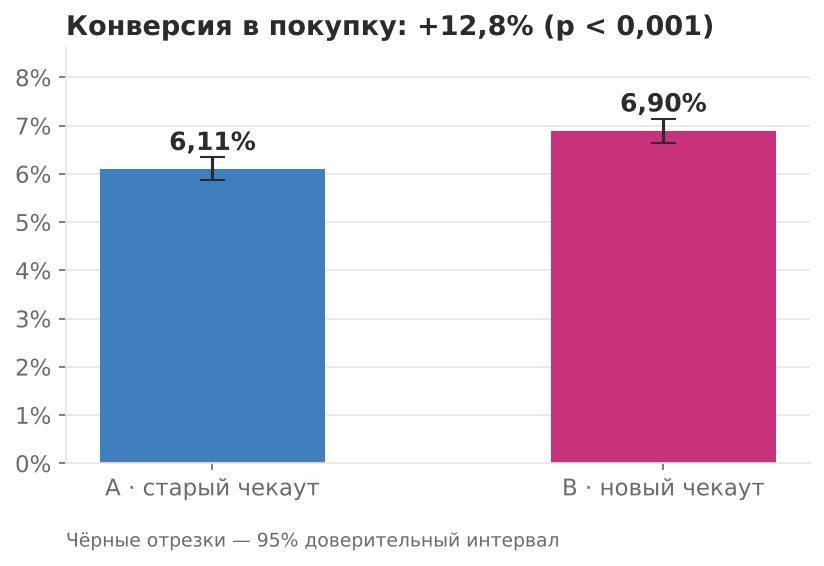

In [6]:
c = res["conversion"]
print(f"A: {c['p_a']:.2%}   B: {c['p_b']:.2%}")
print(f"Прирост: {c['uplift']:+.1%}, 95% ДИ [{c['uplift_ci_low']:+.1%}; {c['uplift_ci_high']:+.1%}], p = {c['p_value']:.5f}")
display(Image("images/01_conversion.png"))

Конверсия выросла на ~13%, и даже нижняя граница интервала (+7%) — заметный эффект.

## 4. Выручка на пользователя (ARPU)

Здесь сложнее: у выручки тяжёлый хвост — несколько оптовых заказов на десятки тысяч рублей. Из-за них обычный t-тест «шумит».

In [7]:
rows = []
for key, name in [("arpu_raw", "Сырой ARPU"), ("arpu_winsor", "Винзоризация 99,5%"), ("arpu_cuped", "Винзоризация + CUPED")]:
    r = res[key]
    rows.append({"метод": name, "A, ₽": r["mean_a"], "B, ₽": r["mean_b"], "прирост": r["uplift"],
                 "ДИ от, ₽": r["ci_low"], "ДИ до, ₽": r["ci_high"], "p-value": r["p_value"]})
pd.DataFrame(rows)

,метод,"A, ₽","B, ₽",прирост,"ДИ от, ₽","ДИ до, ₽",p-value
0,Сырой ARPU,318.8263,337.0549,0.0572,-17.1495,53.6065,0.3126
1,"Винзоризация 99,5%",259.1170,279.7841,0.0798,1.8383,39.4959,0.0315
2,Винзоризация + CUPED,260.1888,278.7092,0.0712,0.5803,36.4604,0.0430


- **Сырой ARPU**: прирост есть, но интервал широкий и включает ноль — из-за выбросов.
- **Винзоризация** (обрезаем выручку пользователя на уровне 99,5-го перцентиля): шум уходит, эффект значим.
- **CUPED** использует выручку пользователя за 30 дней до теста как ковариату. Дисперсия падает ещё на ~9%, интервал сужается. Оценка эффекта чуть ниже: CUPED поправляет случайный перекос — в группе B оказалось немного больше активных покупателей до теста.

Проверим бутстрапом — он не делает допущений о распределении:

Бутстрап: +20.7 ₽, 95% ДИ [+2.3; +39.6], p = 0.0268


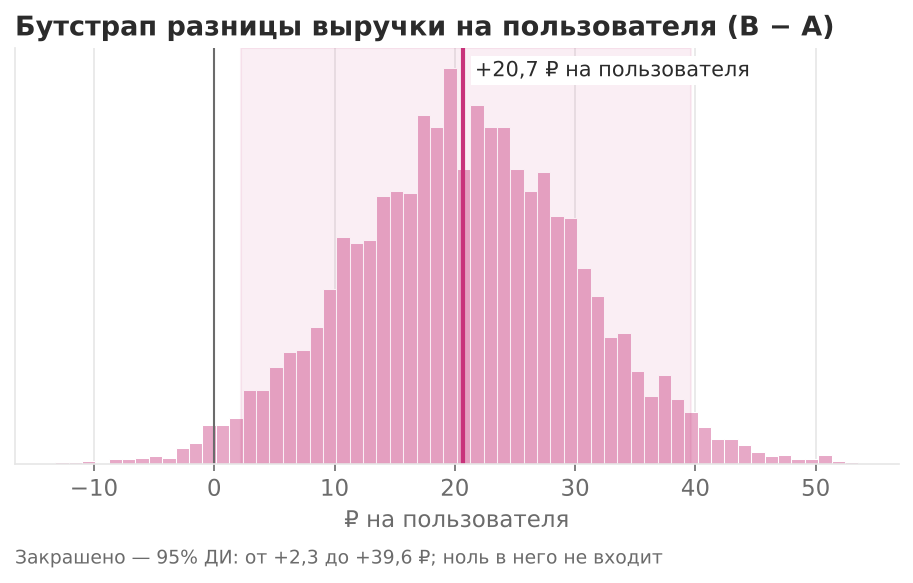

In [8]:
bt = res["arpu_bootstrap"]
print(f"Бутстрап: +{bt['diff']:.1f} ₽, 95% ДИ [{bt['ci_low']:+.1f}; {bt['ci_high']:+.1f}], p = {bt['p_value']:.4f}")
display(Image("images/04_bootstrap_arpu.png"))

## 5. Защитные метрики

In [9]:
print(f"Средний чек: A {res['aov']['A']:,.0f} ₽ → B {res['aov']['B']:,.0f} ₽ ({res['aov']['B']/res['aov']['A']-1:+.1%})")
r = res["refunds"]
print(f"Доля возвратов: A {r['p_a']:.2%} → B {r['p_b']:.2%}, p = {r['p_value']:.3f}")

Средний чек: A 5,003 ₽ → B 4,700 ₽ (-6.1%)
Доля возвратов: A 5.74% → B 6.39%, p = 0.303


Средний чек в B ниже примерно на 6%. Это ожидаемо: простой чекаут «дожимает» покупателей с небольшими корзинами, которые раньше бросали оформление. Покупателей стало больше настолько, что выручка на пользователя всё равно растёт. Возвраты статистически не изменились.

## 6. Сегменты

Смотрим 4 сегмента: устройство × тип пользователя. Сравнений несколько, поэтому применяем поправку Холма — иначе легко «найти» эффект случайно.

In [10]:
res["segments"]

,segment,users,conv_a,conv_b,uplift,ci_low,ci_high,p_value,significant_holm
0,Десктоп · новые,14411,0.0461,0.0467,0.0127,-0.1362,0.1617,0.8671,False
1,Десктоп · постоянные,17339,0.0963,0.1029,0.0690,-0.0236,0.1617,0.1440,False
2,Мобильные · новые,21726,0.0301,0.0388,0.2881,0.1270,0.4491,0.0005,True
3,Мобильные · постоянные,26284,0.0716,0.0839,0.1707,0.0804,0.2611,0.0002,True


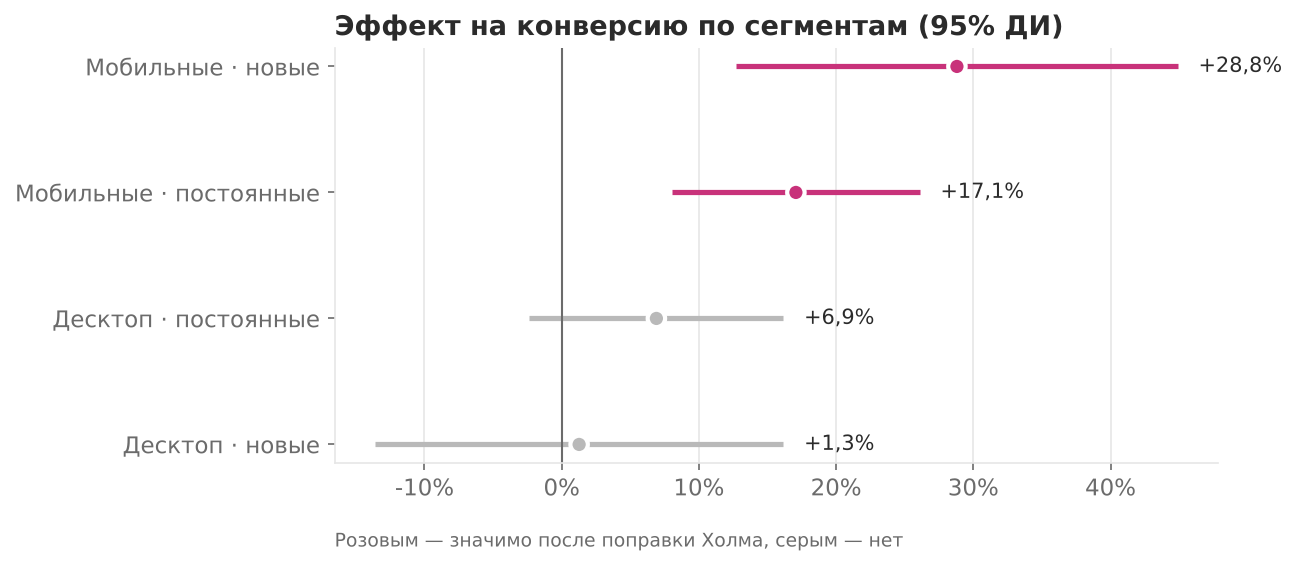

In [11]:
display(Image("images/03_segments.png"))

Весь эффект — на мобильных: +17% у постоянных и +29% у новых пользователей. На десктопе изменения незначимы: старый чекаут и так был удобным на большом экране.

## 7. Эффект новизны

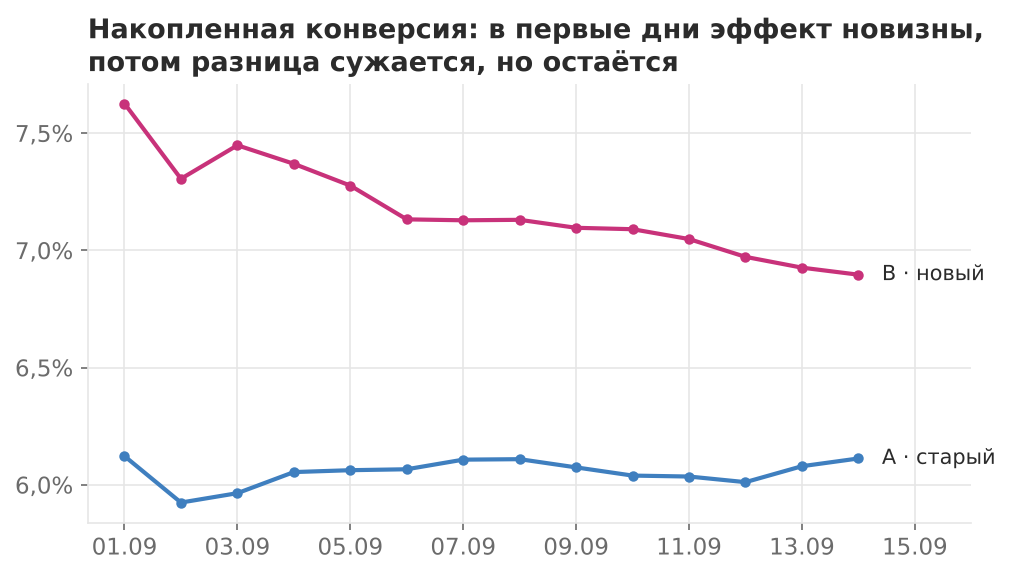

In [12]:
display(Image("images/02_cumulative.png"))

В первые дни разница больше — часть пользователей реагирует на новизну. К концу теста накопленная разница сужается до ~13%, но остаётся устойчиво выше нуля.

## Вывод

**Выкатывать новый чекаут.**

1. Конверсия: **+12,8%** (95% ДИ +7…+18%), p < 0,001.
2. Выручка на пользователя: **+7–8%** после обработки выбросов (винзоризация, бутстрап и CUPED дают один вывод).
3. Средний чек ниже на ~6%, но это компенсируется ростом числа покупателей. Возвраты не изменились.
4. Эффект создают мобильные пользователи. Если ресурсы ограничены, выкатку можно начать с мобильной версии.

**Риски и следующие шаги**
- эффект новизны: после выкатки отслеживать конверсию 3–4 недели;
- десктоп: эффект не доказан; при мощности теста мы могли не заметить прирост меньше ~8%;
- средний чек: добавить в новый чекаут допродажи (например, «добавьте до бесплатной доставки»), чтобы вернуть часть чека.